# Extreme Precipitation Forecasting with GraphCast: 2025 Tennessee Valley Flood

In early April 2025, days of repeated heavy rain caused widespread flooding across the Ohio and Tennessee valleys; the heaviest rain fell on 3 April. This notebook runs Google DeepMind's GraphCast Operational model through NVIDIA Earth2Studio. GraphCast Operational is initialized from the NOAA GFS analysis (the `GFS` data source loaded in section 3) at 2025-04-01 00Z and run for 20 six-hourly steps (5 days, to 2025-04-06 00Z). Daily and cumulative precipitation are mapped over the contiguous U.S. and verified against ERA5 daily precipitation over the Tennessee Valley box (33–40.5°N, 95–82°W). You will learn how to turn GraphCast's 6-hour precipitation steps into daily totals, how to read the maps, and how to score a rainfall forecast against a reanalysis.

> **Measured on an NVIDIA L40:** 6 min runtime · 37.7 GiB peak GPU memory.

1. Setup
2. Configuration
3. Load GraphCast and the GFS initial state
4. Run the forecast
5. Daily and cumulative precipitation
6. Precipitation maps
7. Verify against ERA5

## 1 · Setup

The environment variable must be set before PyTorch starts, so it comes first. `free_gpu(...)` releases PyTorch's cached GPU memory once a forecast is written, even if the cell fails. GraphCast runs in JAX, which keeps the memory it used until the kernel exits, so shut this notebook's kernel down (**Kernel → Shut Down Kernel**) before you open another GPU notebook.

In [1]:
# Environment: must be set before torch / earth2studio are imported.
import os

os.environ["PYTORCH_CUDA_ALLOC_CONF"] = "expandable_segments:True"
os.environ.setdefault("XLA_PYTHON_CLIENT_PREALLOCATE", "false")  # JAX (GraphCast): allocate GPU memory on demand, not ~75% up front

import gc
import shutil
import warnings
from pathlib import Path

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.colors as mcolors
import matplotlib.pyplot as plt
from mpl_toolkits.axes_grid1 import make_axes_locatable
import numpy as np
import pandas as pd
import torch

import earth2studio.run as run
from earth2studio.data import GFS
from earth2studio.io import ZarrBackend
from earth2studio.models.px import GraphCastOperational

from era5_truth import compute_daily_total_precip

warnings.filterwarnings("ignore")

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Device: {device}")


def free_gpu(*names: str) -> None:
    """Delete the named notebook variables (models, tensors), collect garbage, and release cached CUDA memory."""
    scope = globals()
    for name in names:
        scope.pop(name, None)
    gc.collect()
    torch.cuda.empty_cache()


def map_colorbar(fig, ax, mappable, label=None, orientation="vertical", **kwargs):
    '''Colorbar attached to `ax` that is exactly as long as the drawn map (never longer).

    fig.colorbar(..., ax=ax, shrink=...) sizes the bar from the axes box before a map's fixed
    aspect ratio is applied, so on wide maps the bar comes out taller than the map.'''
    side, pad = ("right", 0.1) if orientation == "vertical" else ("bottom", 0.35)
    cax = make_axes_locatable(ax).append_axes(side, size="4%", pad=pad, axes_class=plt.Axes)
    return fig.colorbar(mappable, cax=cax, orientation=orientation, label=label, **kwargs)

Device: cuda


## 2 · Configuration

Every value a reader may want to change lives here: the event, the initial time and length of the forecast, the days to total and map, and where outputs go.

In [2]:
# Event and forecast
EVENT_NAME = "2025 Tennessee Valley Flood"
EVENT_DATE = "2025-04-03"  # day with the heaviest rain
FORECAST_INIT = "2025-04-01T00:00:00"
NSTEPS = 20  # 20 x 6h = Apr 1 00Z -> Apr 6 00Z (last full day is April 5)

# Days to total (all) and to map one by one
DATES = ["2025-04-01", "2025-04-02", "2025-04-03", "2025-04-04", "2025-04-05"]
PLOT_DATES = ["2025-04-03", "2025-04-04", "2025-04-05"]

# Map extent [lon_min, lon_max, lat_min, lat_max]: CONUS + buffer.
# The ERA5 scores in section 7 use the smaller Tennessee Valley box (era5_truth.TN_BOX) instead.
EXTENT = [-128, -63, 18, 55]

# Outputs (paths relative to the notebook folder)
PROJECT = Path.cwd()  # JupyterLab and nbconvert both start in the notebook's folder
OUTPUT_DIR = "tn_flood_outputs"
ZARR_STORE = f"{OUTPUT_DIR}/graphcast_tn_flood.zarr"
RESULTS_DIR = PROJECT / "docs" / "results"  # small CSV metric tables that the README embeds
RESULTS_DIR.mkdir(parents=True, exist_ok=True)
os.makedirs(OUTPUT_DIR, exist_ok=True)
FIG_DIR = PROJECT / "figures"  # PNG figures of all three notebooks, tracked in git
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 3 · Load GraphCast and the GFS initial state

GraphCast Operational was pre-trained on ERA5 and fine-tuned on ECMWF operational (HRES) analyses, and it needs no precipitation input, so an operational analysis such as GFS can start it. GraphCast reads two input times (00Z and the previous 18Z).

In [3]:
package = GraphCastOperational.load_default_package()
model = GraphCastOperational.load_model(package)

# Initial state: the NOAA GFS analysis
data = GFS()

print("Model and data source loaded.")

Model and data source loaded.


## 4 · Run the forecast

`run.deterministic` steps the model forward 6 hours at a time and writes each step to a Zarr store. Only `tp06` (6-hour precipitation) is kept, which keeps the store small.

In [4]:
try:
    store = ZarrBackend(ZARR_STORE, backend_kwargs={"overwrite": True})
    store = run.deterministic(
        [FORECAST_INIT],
        NSTEPS,
        model,
        data,
        store,
        output_coords={"variable": np.array(["tp06"])},
    )
except BaseException:
    shutil.rmtree(ZARR_STORE, ignore_errors=True)  # never leave a half-written forecast on disk
    raise
finally:
    free_gpu("model", "package")

print(store.root.tree())

2026-11-01 05:54:13.071 | INFO     | earth2studio.run:deterministic:85 - Running simple workflow!
2026-11-01 05:54:13.071 | INFO     | earth2studio.run:deterministic:92 - Inference device: cuda
2026-11-01 05:54:13.556 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 209958863-741336
2026-11-01 05:54:13.575 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 192771683-966974
2026-11-01 05:54:13.592 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 220767082-734184
2026-11-01 05:54:13.610 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - Fetching GFS grib file: noaa-gfs-bdp-pds/gfs.20250331/18/atmos/gfs.t18z.pgrb2.0p25.f000 203496506-1031455
2026-11-01 05:54:13.627 | DEBUG    | earth2studio.data.gfs:fetch_array:395 - 

E1101 05:56:19.239358  110947 slow_operation_alarm.cc:74] 
********************************
[Compiling module input_reduce_fusion for GPU] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************
E1101 05:58:05.825617  110941 slow_operation_alarm.cc:141] The operation took 3m46.586340526s

********************************
[Compiling module input_reduce_fusion for GPU] Very slow compile? If you want to file a bug, run with envvar XLA_FLAGS=--xla_dump_to=/tmp/foo and attach the results.
********************************


2026-11-01 05:59:17.467 | SUCCESS  | earth2studio.run:deterministic:189 - 
Inference complete
/
├── lat (721,) float64
├── lead_time (21,) timedelta64[h]
├── lon (1440,) float64
├── time (1,) datetime64[ns]
└── tp06 (1, 21, 721, 1440) float32



## 5 · Daily and cumulative precipitation

Each `tp06` value is the rain (in metres) that fell in the 6 hours ending at that step's valid time; step 0 is the initial state and is all zeros. A UTC day D is therefore the sum of the four steps valid at D 06Z, 12Z, 18Z and D+1 00Z, which is the window (D 00Z, D+1 00Z]. The ERA5 daily totals in section 7 use the same window. Both `compute_daily_total_precip` and the ERA5 daily totals live in `era5_truth.py`, whose unit tests check that the two use the same day.

In [5]:
def compute_cumulative_precip(store, dates, init_time, variable="tp06", dt_hours=6):
    """Sum of the daily totals (mm) over `dates`."""
    return sum(compute_daily_total_precip(store, date, init_time, variable, dt_hours) for date in dates)

In [6]:
PRECIP_CMAP = plt.cm.rainbow_r  # red = light rain, blue-purple = heavy rain


def plot_daily_precip(precip_mm, store, target_date, extent, init_time, model_name="GraphCast", save_path=None):
    """Map one daily precipitation total (mm) on a tall U.S. map; optionally save it as a PNG."""
    plt.close("all")

    lon = store["lon"][:]
    lat = store["lat"][:]

    levels = [1, 5, 10, 20, 30, 50, 75, 100, 150]
    norm = mcolors.BoundaryNorm(levels, PRECIP_CMAP.N)

    fig, ax = plt.subplots(
        subplot_kw={"projection": ccrs.PlateCarree()},
        figsize=(6, 8),
    )

    # totals above the top level are clipped into the top band instead of leaving them blank
    im = ax.contourf(
        lon, lat, np.clip(precip_mm, None, levels[-1]),
        levels=levels, cmap=PRECIP_CMAP, norm=norm,
        transform=ccrs.PlateCarree(),
    )

    ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor="gray")
    ax.add_feature(cfeature.BORDERS, linewidth=0.8)
    ax.coastlines(linewidth=0.8)
    gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
    gl.top_labels = False
    gl.right_labels = False
    gl.xlabel_style = {"size": 8}
    gl.ylabel_style = {"size": 8}
    ax.set_extent(extent)

    map_colorbar(fig, ax, im, label="Total Precipitation (mm)", orientation="horizontal")
    ax.set_title(
        f"{model_name} | Init: {init_time[:10]} | Date: {target_date}",
        fontsize=11,
    )

    plt.tight_layout()
    if save_path:
        fig.savefig(save_path, dpi=150, bbox_inches="tight")
        print(f"Saved: {save_path}")
    plt.show()

## 6 · Precipitation maps

The daily maps show how the forecast rain band evolves through the event; the cumulative map shows where the forecast puts the flood-producing totals.

Saved: /home/jovyan/flood-forecasts/figures/graphcast_daily_2025-04-03.png


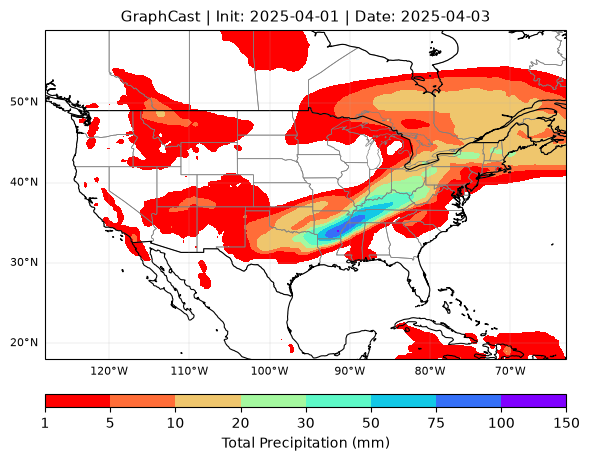

Saved: /home/jovyan/flood-forecasts/figures/graphcast_daily_2025-04-04.png


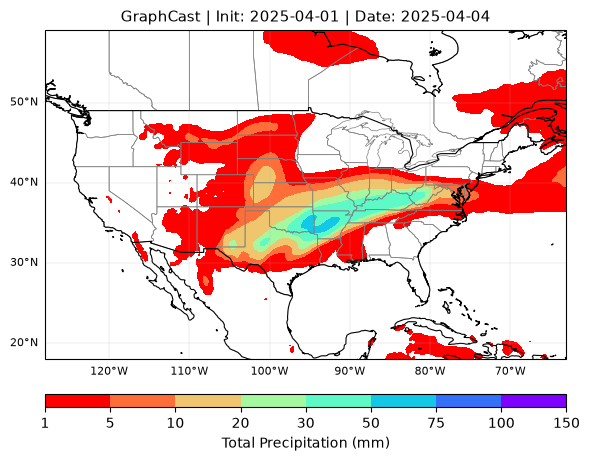

Saved: /home/jovyan/flood-forecasts/figures/graphcast_daily_2025-04-05.png


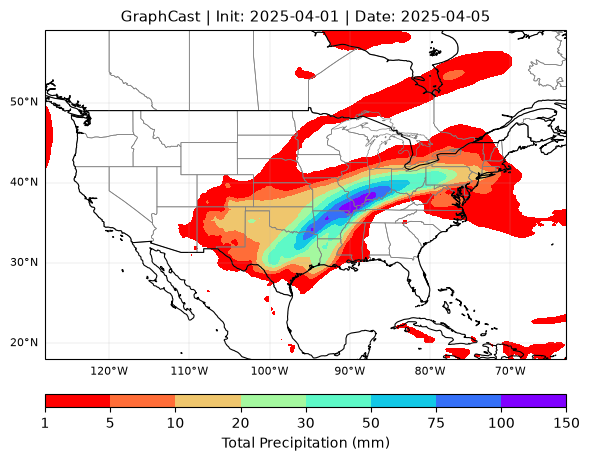

In [7]:
for date in PLOT_DATES:
    precip = compute_daily_total_precip(store, date, FORECAST_INIT)
    plot_daily_precip(
        precip, store, date, EXTENT, FORECAST_INIT,
        save_path=f"{FIG_DIR}/graphcast_daily_{date}.png",
    )

**How to read this.** Each map is one UTC day (00Z to 00Z) of forecast rain from the same 1 April run, so 3 April is a 3-day forecast and 5 April a 5-day forecast. Colours run from red (light, from 1 mm) to blue-purple (heavy: the top band is 100 to 150 mm, and totals above 150 mm share its colour); white means less than 1 mm. Look at where the heaviest band sits relative to the Tennessee and Ohio valleys and how it shifts from day to day.

Saved: /home/jovyan/flood-forecasts/figures/graphcast_cumulative_apr1_5.png


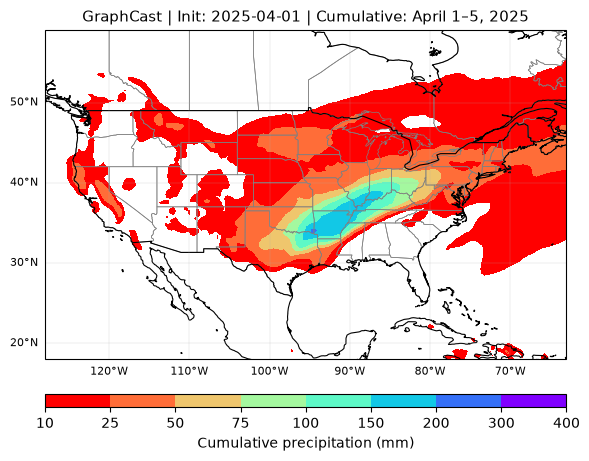

In [8]:
cumulative = compute_cumulative_precip(store, DATES, FORECAST_INIT)

plt.close("all")

lon = store["lon"][:]
lat = store["lat"][:]

levels = [10, 25, 50, 75, 100, 150, 200, 300, 400]
norm = mcolors.BoundaryNorm(levels, PRECIP_CMAP.N)

fig, ax = plt.subplots(
    subplot_kw={"projection": ccrs.PlateCarree()},
    figsize=(6, 8),
)

im = ax.contourf(
    lon, lat, np.clip(cumulative, None, levels[-1]),
    levels=levels, cmap=PRECIP_CMAP, norm=norm,
    transform=ccrs.PlateCarree(),
)

ax.add_feature(cfeature.STATES, linewidth=0.5, edgecolor="gray")
ax.add_feature(cfeature.BORDERS, linewidth=0.8)
ax.coastlines(linewidth=0.8)
gl = ax.gridlines(draw_labels=True, linewidth=0.3, alpha=0.5)
gl.top_labels = False
gl.right_labels = False
gl.xlabel_style = {"size": 8}
gl.ylabel_style = {"size": 8}
ax.set_extent(EXTENT)

map_colorbar(fig, ax, im, label="Cumulative precipitation (mm)", orientation="horizontal")
ax.set_title(
    f"GraphCast | Init: {FORECAST_INIT[:10]} | Cumulative: April 1–5, 2025",
    fontsize=11,
)

plt.tight_layout()
fig.savefig(f"{FIG_DIR}/graphcast_cumulative_apr1_5.png", dpi=150, bbox_inches="tight")
print(f"Saved: {FIG_DIR}/graphcast_cumulative_apr1_5.png")

plt.show()

**How to read this.** This is the sum of the five daily totals for 1–5 April, on the same red-to-blue-purple scale but with levels from 10 to 400 mm; totals above 400 mm are drawn in the top band (300 to 400 mm), so they share its colour. The flood-producing rain is the long band of large totals; compare its position with the Tennessee Valley box (33–40.5°N, 95–82°W) that is scored in section 7.

## 7 · Verify against ERA5

How close is the forecast to an independent estimate of the rain that fell? Each daily forecast total is compared with the ERA5 daily total for the same UTC window (section 5), over the Tennessee Valley box (33–40.5°N, 95–82°W, `era5_truth.TN_BOX`) on the model's 0.25° grid. Hourly ERA5 precipitation comes from the Copernicus Climate Data Store (it needs `~/.cdsapirc` credentials) and is cached in `OUTPUT_DIR`.

> **Truth caveat:** ERA5 precipitation is itself model-derived (it is a reanalysis product), so these scores measure agreement with ERA5, not with rain gauges or radar.

**How to read the table.** One row per forecast day (lead day 1 = 1 April) plus a row for the 1–5 April total. Bias = forecast − ERA5 in mm/day (positive means too wet), averaged over the box with area weights; RMSE and MAE are the typical size of the point-by-point error in mm/day; Pattern corr = spatial correlation of the daily rainfall pattern (1 means the rain is in the right places, whatever the amounts). The total row is in mm over the five days. The last line compares the area-mean 5-day totals and gives the forecast's percentage bias. Errors usually grow with lead day.

In [9]:
from era5_truth import TN_ERA5_AREA, fetch_era5_daily_precip, forecast_vs_era5
from metrics import event_total_error, skill_row

era5_daily = fetch_era5_daily_precip(DATES, TN_ERA5_AREA, f"{OUTPUT_DIR}/era5_tp_tn.nc")
lat, lon = store["lat"][:], store["lon"][:]

rows = []
for date in DATES:
    fc, ref, lats = forecast_vs_era5(
        compute_daily_total_precip(store, date, FORECAST_INIT),
        era5_daily.sel(day=np.datetime64(date)), lat, lon,
    )
    lead_day = int((np.datetime64(date) - np.datetime64(FORECAST_INIT[:10])).astype(int)) + 1
    rows.append({"Lead day": lead_day, "Date": date, **skill_row(fc, ref, lats)})

fc_total, ref_total, lats = forecast_vs_era5(
    compute_cumulative_precip(store, DATES, FORECAST_INIT),
    era5_daily.sel(day=[np.datetime64(d) for d in DATES]).sum("day", min_count=len(DATES)), lat, lon,
)
rows.append({"Lead day": "Apr 1-5 total", "Date": "", **skill_row(fc_total, ref_total, lats)})

daily_skill = pd.DataFrame(rows)
daily_skill.to_csv(RESULTS_DIR / "graphcast_tennessee_valley_flood_metrics.csv", index=False)
print("GraphCast vs ERA5 over the Tennessee Valley box (mm/day; Bias = forecast - ERA5)\n")
print(daily_skill.to_string(index=False))
print("\nEvent total (area means, mm):", event_total_error(fc_total, ref_total, lats))

2026-11-01 05:59:27,436 INFO [2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
INFO:ecmwf.datastores.legacy_client:[2026-10-06T00:00:00Z] **Data Stores Service protection measures** affecting data downloads and account access: [please read our Announcement](https://forum.ecmwf.int/t/data-stores-service-protection-measures-affecting-data-downloads-and-account-access-cds-ads-ewds-ecds/15481) before enquiring with ECMWF Support.
2026-11-01 05:59:28,132 INFO Request ID is ad00a134-0515-4292-b467-48de47bac8a2
INFO:ecmwf.datastores.legacy_client:Request ID is ad00a134-0515-4292-b467-48de47bac8a2
2026-11-01 05:59:28,312 INFO status has been updated to successful
INFO:ecmwf.datastores.legacy_client:status has been updated to successf

GraphCast vs ERA5 over the Tennessee Valley box (mm/day; Bias = forecast - ERA5)

     Lead day       Date   Bias   RMSE    MAE  Pattern corr
            1 2025-04-01  0.144  0.460  0.215         0.707
            2 2025-04-02 -0.431  7.778  4.893         0.789
            3 2025-04-03 -0.470 14.781  8.944         0.830
            4 2025-04-04  3.741 12.956  9.019         0.752
            5 2025-04-05  2.233 20.962 13.355         0.807
Apr 1-5 total             5.217 31.830 21.966         0.900

Event total (area means, mm): {'Forecast area-mean': 84.3, 'Reference area-mean': 79.0, 'Total bias (%)': 6.6}


## Summary

- **Daily maps (section 6):** where did GraphCast put the heaviest rain on 3–5 April, and how did the band move as the lead time grew?
- **Cumulative map (section 6):** where does the forecast concentrate the 1–5 April total, and does that band cover the Tennessee and Ohio valleys?
- **ERA5 skill table (section 7):** over the Tennessee Valley box, is the forecast too wet or too dry (Bias), how large are the errors (RMSE, MAE), and is the rain in the right places (Pattern corr)? Watch how these change with lead day, and remember that ERA5 precipitation is itself model-derived.

The scores are saved to `docs/results/graphcast_tennessee_valley_flood_metrics.csv`; the map PNGs are in `figures/`.